In [1]:
# ============================================================
# REALISTIC MAIN ASTEROID BELT N-BODY SIMULATION
#
# Sun + 8 planetary systems + 4 major asteroids
#
# Initial states : NASA/JPL Horizons
# Asteroid data  : NASA/JPL SBDB
# Integration    : Our own RK4
# Units          : km, s, km/s
# ============================================================


# ============================================================
# PART 1 — IMPORT LIBRARIES
# ============================================================

import numpy as np
import requests
import re
import time

import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from datetime import datetime, timedelta

In [2]:
# ============================================================
# PART 2 — BASIC CONSTANTS
# ============================================================

HORIZONS_URL = "https://ssd.jpl.nasa.gov/api/horizons.api"

SBDB_URL = "https://ssd-api.jpl.nasa.gov/sbdb.api"


# Initial epoch
# We use the SAME time for every body.

EPOCH = "2026-Oct-21 00:00:00"


# Solar System barycenter
CENTER = "@0"


# Astronomical Unit in km
AU_KM = 149597870.7


# Seconds in one day
DAY = 86400.0

In [3]:
# ============================================================
# PART 3 — JPL HORIZONS SETTINGS
# ============================================================

base_params = {

    "format": "json",

    "OBJ_DATA": "'NO'",

    "MAKE_EPHEM": "'YES'",

    "EPHEM_TYPE": "'VECTORS'",

    # Solar System barycenter
    "CENTER": "'@0'",

    # Calendar time
    "TLIST_TYPE": "'CAL'",

    # Dynamical time
    "TIME_TYPE": "'TDB'",

    # International Celestial Reference Frame
    "REF_SYSTEM": "'ICRF'",

    "REF_PLANE": "'FRAME'",

    # km and km/s
    "OUT_UNITS": "'KM-S'",

    # position + velocity
    "VEC_TABLE": "'2'",

    # geometric vectors
    "VEC_CORR": "'NONE'",

    "CSV_FORMAT": "'NO'",

    "VEC_LABELS": "'YES'"
}

In [4]:
# ============================================================
# PART 4 — EXTRACT A STATE VECTOR FROM JPL
# ============================================================

def get_state(command, epoch=EPOCH):

    params = base_params.copy()

    params["COMMAND"] = f"'{command}'"

    params["TLIST"] = f"'{epoch}'"


    response = requests.get(
        HORIZONS_URL,
        params=params,
        timeout=30
    )

    response.raise_for_status()

    result = response.json()["result"]


    if "$$SOE" not in result:

        raise RuntimeError(
            f"No vector data returned for command {command}"
        )


    vector_data = (
        result
        .split("$$SOE")[1]
        .split("$$EOE")[0]
    )


    # --------------------------------------------------------
    # Number pattern
    # --------------------------------------------------------

    number = r"([+\-0-9.Ee]+)"


    # --------------------------------------------------------
    # Position
    # --------------------------------------------------------

    x = float(
        re.search(
            rf"X\s*=\s*{number}",
            vector_data
        ).group(1)
    )

    y = float(
        re.search(
            rf"Y\s*=\s*{number}",
            vector_data
        ).group(1)
    )

    z = float(
        re.search(
            rf"Z\s*=\s*{number}",
            vector_data
        ).group(1)
    )


    # --------------------------------------------------------
    # Velocity
    # --------------------------------------------------------

    vx = float(
        re.search(
            rf"VX\s*=\s*{number}",
            vector_data
        ).group(1)
    )

    vy = float(
        re.search(
            rf"VY\s*=\s*{number}",
            vector_data
        ).group(1)
    )

    vz = float(
        re.search(
            rf"VZ\s*=\s*{number}",
            vector_data
        ).group(1)
    )


    position = np.array(
        [x, y, z],
        dtype=float
    )


    velocity = np.array(
        [vx, vy, vz],
        dtype=float
    )


    return position, velocity

In [5]:
# ============================================================
# PART 5 — OBJECTS WE WILL SIMULATE
# ============================================================

bodies = {

    "Sun": "10",

    # Planetary system barycenters

    "Mercury": "1",

    "Venus": "2",

    "Earth-Moon": "3",

    "Mars": "4",

    "Jupiter": "5",

    "Saturn": "6",

    "Uranus": "7",

    "Neptune": "8",


    # Asteroids
    # semicolon forces small-body search

    "Ceres": "1;",

    "Pallas": "2;",

    "Vesta": "4;",

    "Hygiea": "10;"
}

In [6]:
# ============================================================
# PART 6 — DOWNLOAD REAL INITIAL POSITIONS AND VELOCITIES
# ============================================================

states = {}


for name, command in bodies.items():

    print("Downloading:", name)

    position, velocity = get_state(
        command,
        EPOCH
    )


    states[name] = {

        "position": position,

        "velocity": velocity
    }


    time.sleep(0.1)


print()
print("All JPL initial states downloaded.")

Downloading: Sun
Downloading: Mercury
Downloading: Venus
Downloading: Earth-Moon
Downloading: Mars
Downloading: Jupiter
Downloading: Saturn
Downloading: Uranus
Downloading: Neptune
Downloading: Ceres
Downloading: Pallas
Downloading: Vesta
Downloading: Hygiea

All JPL initial states downloaded.


In [7]:
print("Ceres position [km]:")
print(states["Ceres"]["position"])

print()

print("Ceres velocity [km/s]:")
print(states["Ceres"]["velocity"])

Ceres position [km]:
[1.03736949e+07 3.59651056e+08 1.67537537e+08]

Ceres velocity [km/s]:
[-18.28653843  -2.1525376    2.70904987]


In [8]:
# ============================================================
# PART 7 — PLANETARY GM VALUES
# ============================================================

GM = {

    "Sun":
        1.32712440041279419e11,

    "Mercury":
        22031.868551,

    "Venus":
        324858.592000,

    # Earth + Moon
    "Earth-Moon":
        398600.435507
        + 4902.800118,

    "Mars":
        42828.375816,

    "Jupiter":
        126712764.100000,

    "Saturn":
        37940584.841800,

    "Uranus":
        5794556.400000,

    "Neptune":
        6836527.100580
}

In [9]:
# ============================================================
# PART 8 — GET ASTEROID GM FROM NASA/JPL SBDB
# ============================================================

def get_asteroid_gm(name):

    parameters = {

        "sstr": name,

        "phys-par": "1",

        "full-prec": "1"
    }


    response = requests.get(
        SBDB_URL,
        params=parameters,
        timeout=30
    )

    response.raise_for_status()

    data = response.json()


    for parameter in data.get("phys_par", []):

        if parameter["name"] == "GM":

            return float(
                parameter["value"]
            )


    raise RuntimeError(
        f"JPL SBDB did not return GM for {name}"
    )

In [10]:
asteroids = [
    "Ceres",
    "Pallas",
    "Vesta",
    "Hygiea"
]


for name in asteroids:

    GM[name] = get_asteroid_gm(name)

    print(
        name,
        "GM =",
        GM[name],
        "km^3/s^2"
    )

Ceres GM = 62.6284 km^3/s^2
Pallas GM = 13.63 km^3/s^2
Vesta GM = 17.2882844 km^3/s^2
Hygiea GM = 7.0 km^3/s^2


In [11]:
# ============================================================
# PART 9 — BODY LIST
# ============================================================

body_names = list(states.keys())

print(body_names)

print()

print(
    "Number of simulated bodies:",
    len(body_names)
)

['Sun', 'Mercury', 'Venus', 'Earth-Moon', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune', 'Ceres', 'Pallas', 'Vesta', 'Hygiea']

Number of simulated bodies: 13


In [12]:
# ============================================================
# PART 10 — POSITION ARRAY
# ============================================================

positions = np.array([

    states[name]["position"]

    for name in body_names

])

print(
    "Position array shape:",
    positions.shape
)

Position array shape: (13, 3)


In [13]:
# ============================================================
# PART 11 — VELOCITY ARRAY
# ============================================================

velocities = np.array([

    states[name]["velocity"]

    for name in body_names

])

print(
    "Velocity array shape:",
    velocities.shape
)

Velocity array shape: (13, 3)


In [14]:
# ============================================================
# PART 12 — ACCELERATION OF ALL BODIES
# ============================================================

def all_accelerations(positions):

    accelerations = np.zeros_like(
        positions
    )


    for i, name_i in enumerate(body_names):


        for j, name_j in enumerate(body_names):


            # Body cannot pull itself

            if i == j:
                continue


            # Vector from i toward j

            r_vector = (
                positions[j]
                -
                positions[i]
            )


            distance = np.linalg.norm(
                r_vector
            )


            accelerations[i] += (

                GM[name_j]

                * r_vector

                / distance**3
            )


    return accelerations

In [15]:
accelerations = all_accelerations(
    positions
)

i = body_names.index("Ceres")

print(
    "Ceres acceleration:"
)

print(
    accelerations[i]
)

print()

print(
    "Magnitude:",
    np.linalg.norm(
        accelerations[i]
    ),
    "km/s^2"
)

Ceres acceleration:
[-2.25823177e-08 -7.60412023e-07 -3.54151295e-07]

Magnitude: 8.391421488300581e-07 km/s^2


In [16]:
# ============================================================
# PART 13 — EQUATIONS OF MOTION
# ============================================================

def derivatives(
    positions,
    velocities
):

    # dr/dt = velocity

    dpos_dt = velocities


    # dv/dt = acceleration

    dvel_dt = all_accelerations(
        positions
    )


    return (
        dpos_dt,
        dvel_dt
    )

In [17]:
# ============================================================
# PART 14 — ONE RK4 STEP
# ============================================================

def rk4_step(
    positions,
    velocities,
    dt
):

    # ------------------------
    # k1
    # ------------------------

    k1_r, k1_v = derivatives(
        positions,
        velocities
    )


    # ------------------------
    # k2
    # ------------------------

    k2_r, k2_v = derivatives(

        positions
        + 0.5 * dt * k1_r,

        velocities
        + 0.5 * dt * k1_v
    )


    # ------------------------
    # k3
    # ------------------------

    k3_r, k3_v = derivatives(

        positions
        + 0.5 * dt * k2_r,

        velocities
        + 0.5 * dt * k2_v
    )


    # ------------------------
    # k4
    # ------------------------

    k4_r, k4_v = derivatives(

        positions
        + dt * k3_r,

        velocities
        + dt * k3_v
    )


    # ------------------------
    # New position
    # ------------------------

    new_positions = positions + (

        dt / 6.0

    ) * (

        k1_r

        + 2 * k2_r

        + 2 * k3_r

        + k4_r
    )


    # ------------------------
    # New velocity
    # ------------------------

    new_velocities = velocities + (

        dt / 6.0

    ) * (

        k1_v

        + 2 * k2_v

        + 2 * k3_v

        + k4_v
    )


    return (
        new_positions,
        new_velocities
    )

In [18]:
# ============================================================
# PART 15 — SIMULATION SETTINGS
# ============================================================

dt = 24* 3600.0


# Five years

days = 365 * 12


steps = int(

    days * DAY / dt

)


print(
    "Number of RK4 steps:",
    steps
)

Number of RK4 steps: 4380


In [19]:
# ============================================================
# PART 16 — RUN THE SIMULATION
# ============================================================

trajectory = []

velocity_trajectory = []


current_positions = positions.copy()

current_velocities = velocities.copy()


for step in range(steps):


    trajectory.append(

        current_positions.copy()

    )


    velocity_trajectory.append(

        current_velocities.copy()

    )


    current_positions, current_velocities = rk4_step(

        current_positions,

        current_velocities,

        dt
    )


    # Show progress occasionally

    if step % 500 == 0:

        print(
            "step",
            step,
            "/",
            steps
        )


# Add final state

trajectory.append(
    current_positions.copy()
)

velocity_trajectory.append(
    current_velocities.copy()
)


trajectory = np.array(
    trajectory
)

velocity_trajectory = np.array(
    velocity_trajectory
)


print()

print(
    "Trajectory shape:",
    trajectory.shape
)

step 0 / 4380
step 500 / 4380
step 1000 / 4380
step 1500 / 4380
step 2000 / 4380
step 2500 / 4380
step 3000 / 4380
step 3500 / 4380
step 4000 / 4380

Trajectory shape: (4381, 13, 3)


In [20]:
# ============================================================
# PART 17 — TOTAL SCALED ENERGY
# ============================================================

def total_energy(
    positions,
    velocities
):

    kinetic = 0.0

    potential = 0.0


    # ------------------------
    # Kinetic energy
    # ------------------------

    for i, name in enumerate(body_names):

        velocity_squared = np.dot(

            velocities[i],

            velocities[i]
        )


        kinetic += (

            0.5

            * GM[name]

            * velocity_squared
        )


    # ------------------------
    # Potential energy
    # ------------------------

    for i in range(
        len(body_names)
    ):


        for j in range(
            i + 1,
            len(body_names)
        ):


            distance = np.linalg.norm(

                positions[j]
                -
                positions[i]
            )


            potential -= (

                GM[body_names[i]]

                * GM[body_names[j]]

                / distance
            )


    return (
        kinetic
        +
        potential
    )

In [21]:
initial_energy = total_energy(
    positions,
    velocities
)


final_energy = total_energy(
    current_positions,
    current_velocities
)


energy_error = abs(

    (
        final_energy
        -
        initial_energy
    )

    /
    initial_energy
)


print(
    "Initial energy:",
    initial_energy
)

print(
    "Final energy:",
    final_energy
)

print(
    "Relative energy error:",
    energy_error
)

Initial energy: -13219408388.744314
Final energy: -13219409707.563774
Relative energy error: 9.976387907329288e-08


Number of points: 4381
Initial energy: -13219408388.744314
Final energy: -13219409707.563774
Maximum absolute energy error: 9.976387907329288e-08


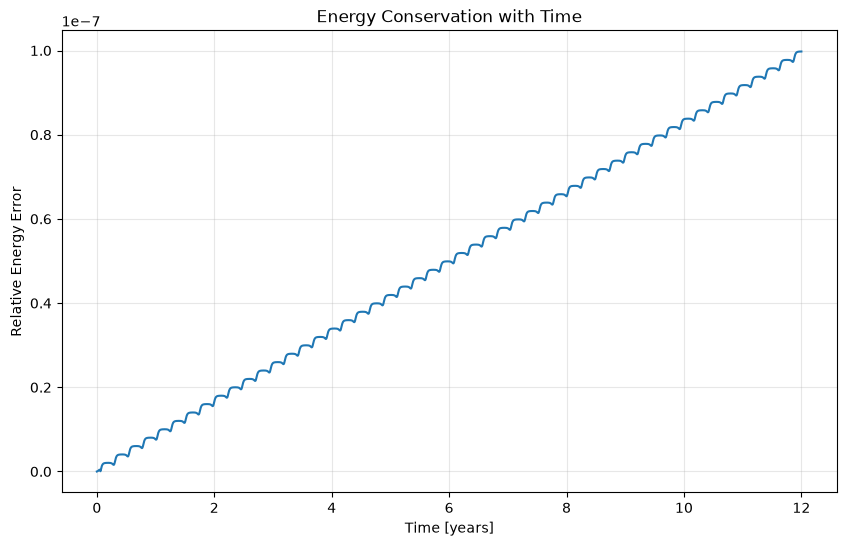

In [22]:
# ============================================================
# ENERGY CONSERVATION WITH TIME
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# Close any old/unfinished figures
plt.close("all")


# ============================================================
# CALCULATE ENERGY AT EVERY TIME STEP
# ============================================================

energy_history = np.zeros(len(trajectory))


for i in range(len(trajectory)):

    energy_history[i] = total_energy(
        trajectory[i],
        velocity_trajectory[i]
    )


# ============================================================
# TIME IN YEARS
# ============================================================

time_years = (
    np.arange(len(trajectory))
    * dt
    / DAY
    / 365.0
)


# ============================================================
# RELATIVE ENERGY ERROR
# ============================================================

E0 = energy_history[0]


relative_energy_error = abs(
    (energy_history - E0)
    / abs(E0)
)


# ============================================================
# CHECK DATA FIRST
# ============================================================

print("Number of points:", len(energy_history))

print(
    "Initial energy:",
    energy_history[0]
)

print(
    "Final energy:",
    energy_history[-1]
)

print(
    "Maximum absolute energy error:",
    np.max(np.abs(relative_energy_error))
)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)


ax.plot(
    time_years,
    relative_energy_error,
    linewidth=1.5
)


ax.set_xlabel(
    "Time [years]"
)

ax.set_ylabel(
    "Relative Energy Error"
)

ax.set_title(
    "Energy Conservation with Time"
)


ax.grid(
    True,
    alpha=0.3
)


# Show y-axis in scientific notation
ax.ticklabel_format(
    axis="y",
    style="sci",
    scilimits=(0, 0)
)


plt.show()

In [23]:
# ============================================================
# PART 18 — ANGULAR MOMENTUM
# ============================================================

def total_angular_momentum(
    positions,
    velocities
):

    L = np.zeros(3)


    for i, name in enumerate(body_names):

        L += (

            GM[name]

            * np.cross(

                positions[i],

                velocities[i]
            )
        )


    return L

In [24]:
L_initial = total_angular_momentum(
    positions,
    velocities
)


L_final = total_angular_momentum(
    current_positions,
    current_velocities
)


angular_momentum_error = (

    np.linalg.norm(
        L_final - L_initial
    )

    /

    np.linalg.norm(
        L_initial
    )
)


print(
    "Relative angular momentum error:",
    angular_momentum_error
)

Relative angular momentum error: 5.422513555465939e-10


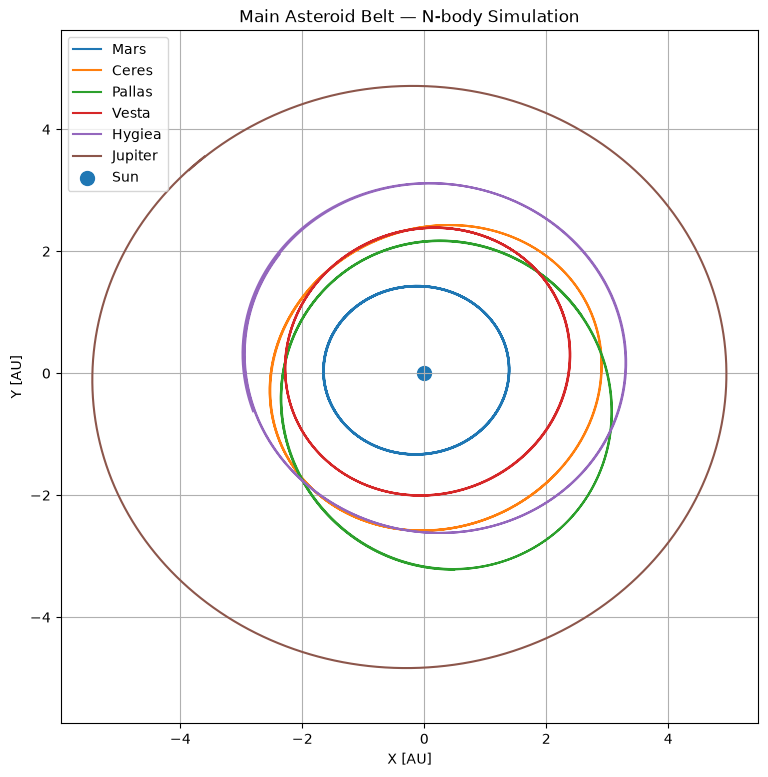

In [25]:
# ============================================================
# PART 19 — STATIC 2D PLOT
# ============================================================

plt.figure(
    figsize=(9, 9)
)


plot_bodies = [

    "Mars",
    "Ceres",
    "Pallas",
    "Vesta",
    "Hygiea",
    "Jupiter"
]


for name in plot_bodies:

    i = body_names.index(name)


    x = (
        trajectory[:, i, 0]
        /
        AU_KM
    )


    y = (
        trajectory[:, i, 1]
        /
        AU_KM
    )


    plt.plot(
        x,
        y,
        label=name
    )


sun_i = body_names.index(
    "Sun"
)


plt.scatter(

    trajectory[0, sun_i, 0]
    / AU_KM,

    trajectory[0, sun_i, 1]
    / AU_KM,

    s=100,

    label="Sun"
)


plt.xlabel(
    "X [AU]"
)

plt.ylabel(
    "Y [AU]"
)


plt.title(
    "Main Asteroid Belt — N-body Simulation"
)


plt.axis(
    "equal"
)


plt.legend()

plt.grid()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.animation import FFMpegWriter


# ============================================================
# CONSTANTS
# ============================================================

DAY = 24 * 3600
AU_KM = 149597870.7

# Simulation timestep
dt = 1 * DAY


# ============================================================
# BODIES TO SHOW
# ============================================================

show_bodies = [
    "Sun",
    "Mars",
    "Ceres",
    "Vesta",
    "Pallas",
    "Hygiea",
    "Jupiter",
    
]


# ============================================================
# CREATE FIGURE
# ============================================================

fig = plt.figure(
    figsize=(10, 9)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


ax.set_xlabel("X [AU]")
ax.set_ylabel("Y [AU]")
ax.set_zlabel("Z [AU]")


# ============================================================
# CREATE MOVING OBJECTS AND ORBIT TRAILS
# ============================================================

points = {}
trails = {}


for name in show_bodies:

    # Moving body
    point, = ax.plot(
        [],
        [],
        [],
        "o",
        markersize=6,
        label=name
    )

    # Orbit traced by body
    trail, = ax.plot(
        [],
        [],
        [],
        linewidth=1.0,
        alpha=0.75
    )

    points[name] = point
    trails[name] = trail


ax.legend(
    loc="upper right"
)


# ============================================================
# FIND BODY INDICES
# ============================================================

show_indices = [

    body_names.index(name)

    for name in show_bodies
]


# ============================================================
# CONVERT TRAJECTORY KM → AU
# ============================================================

trajectory_au = (
    trajectory
    /
    AU_KM
)


selected_positions = (

    trajectory_au[
        :,
        show_indices,
        :
    ]
)


# ============================================================
# SET X AND Y AXIS LIMITS
# ============================================================

max_xy = np.max(

    np.abs(

        selected_positions[
            :,
            :,
            :2
        ]
    )
)


max_xy *= 1.10


ax.set_xlim(
    -max_xy,
    max_xy
)

ax.set_ylim(
    -max_xy,
    max_xy
)


# ============================================================
# SET Z AXIS LIMITS
# ============================================================

max_z = np.max(

    np.abs(

        selected_positions[
            :,
            :,
            2
        ]
    )
)


max_z *= 1.3


if max_z == 0:

    max_z = 1


ax.set_zlim(
    -max_z,
    max_z
)


# ============================================================
# FRAME SKIPPING
# ============================================================

# Simulation:
#     1 numerical step = 1 day
#
# Animation:
#     show one frame every 10 simulated days

frame_skip = 10


animation_frames = range(

    0,

    len(trajectory),

    frame_skip
)


print(
    "Total simulation steps:",
    len(trajectory)
)


print(
    "Animation frames:",
    len(animation_frames)
)


# ============================================================
# UPDATE FUNCTION
# ============================================================

def update(frame):


    for name in show_bodies:


        i = body_names.index(
            name
        )


        # ====================================================
        # CURRENT POSITION OF BODY
        # ====================================================

        x = (

            trajectory[
                frame,
                i,
                0
            ]

            /
            AU_KM
        )


        y = (

            trajectory[
                frame,
                i,
                1
            ]

            /
            AU_KM
        )


        z = (

            trajectory[
                frame,
                i,
                2
            ]

            /
            AU_KM
        )


        points[name].set_data(
            [x],
            [y]
        )


        points[name].set_3d_properties(
            [z]
        )


        # ====================================================
        # TRACE COMPLETE ORBIT
        # ====================================​================

        # Important:
        #
        # Instead of keeping only the last 200 days,
        # we start from simulation step 0.
        #
        # Therefore the orbit grows behind the object.

        x_trail = (

            trajectory[
                0:frame + 1,
                i,
                0
            ]

            /
            AU_KM
        )


        y_trail = (

            trajectory[
                0:frame + 1,
                i,
                1
            ]

            /
            AU_KM
        )


        z_trail = (

            trajectory[
                0:frame + 1,
                i,
                2
            ]

            /
            AU_KM
        )


        trails[name].set_data(
            x_trail,
            y_trail
        )


        trails[name].set_3d_properties(
            z_trail
        )


    # ========================================================
    # SIMULATION TIME
    # ========================================================

    elapsed_days = (

        frame
        *
        dt
        /
        DAY
    )


    elapsed_years = (

        elapsed_days
        /
        365.25
    )


    ax.set_title(

        "Main Asteroid Belt Dynamics\n"

        f"Time = {elapsed_days:.0f} days "

        f"({elapsed_years:.2f} years)"
    )


    return (

        list(
            points.values()
        )

        +

        list(
            trails.values()
        )
    )


# ============================================================
# CREATE ANIMATION
# ============================================================

anim = animation.FuncAnimation(

    fig,

    update,

    frames=animation_frames,

    interval=30,

    blit=False,

    repeat=False
)


# ============================================================
# SAVE AS MP4 VIDEO
# ============================================================

writer = FFMpegWriter(

    fps=30,

    metadata={

        "title":
        "Main Asteroid Belt Dynamics",

        "artist":
        "Matplotlib"
    },

    bitrate=3000
)


anim.save(

    "asteroid_belt_12_years.mp4",

    writer=writer,

    dpi=150
)


print(
    "Video saved as asteroid_belt_12_years.mp4"
)


# ============================================================
# CREATE ANIMATION
# ============================================================

anim = animation.FuncAnimation(
    fig,
    update,
    frames=animation_frames,
    interval=30,
    blit=False,
    repeat=False
)


# ============================================================
# SAVE AS MP4
# ============================================================

writer = FFMpegWriter(
    fps=30,
    metadata={
        "title": "Main Asteroid Belt Dynamics"
    },
    bitrate=3000
)


video_name = "asteroid_belt_12_years.mp4"


anim.save(
    video_name,
    writer=writer,
    dpi=150
)


print("Video saved:", video_name)


# ============================================================
# CLOSE MATPLOTLIB FIGURE
# ============================================================

plt.close(fig)


# ============================================================
# DISPLAY VIDEO IN JUPYTER
# ============================================================

from IPython.display import Video, display

display(
    Video(
        video_name,
        embed=True,
        width=900
    )
)

Total simulation steps: 4381
Animation frames: 439
Video saved as asteroid_belt_12_years.mp4


In [ ]:
%matplotlib widget

In [ ]:
# ============================================================
# 3D SNAPSHOT / STATIC TRAJECTORY PLOT
# ============================================================

import matplotlib.pyplot as plt


# Bodies we want to show

plot_bodies = [
    "Sun",
    "Mars",
    "Jupiter",
    "Ceres",
    "Pallas",
    "Vesta",
    "Hygiea"
]


# ------------------------------------------------------------
# Create 3D figure
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(10, 9)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


# ------------------------------------------------------------
# Plot complete trajectories
# ------------------------------------------------------------

for name in plot_bodies:

    i = body_names.index(name)

    x = trajectory[:, i, 0] / AU_KM
    y = trajectory[:, i, 1] / AU_KM
    z = trajectory[:, i, 2] / AU_KM

    ax.plot(
        x,
        y,
        z,
        label=name
    )


# ------------------------------------------------------------
# Mark the final position of each body
# ------------------------------------------------------------

for name in plot_bodies:

    i = body_names.index(name)

    x_final = trajectory[-1, i, 0] / AU_KM
    y_final = trajectory[-1, i, 1] / AU_KM
    z_final = trajectory[-1, i, 2] / AU_KM

    ax.scatter(
        x_final,
        y_final,
        z_final,
        s=40
    )


# ------------------------------------------------------------
# Highlight the Sun
# ------------------------------------------------------------

sun_i = body_names.index("Sun")

sun_x = trajectory[-1, sun_i, 0] / AU_KM
sun_y = trajectory[-1, sun_i, 1] / AU_KM
sun_z = trajectory[-1, sun_i, 2] / AU_KM

ax.scatter(
    sun_x,
    sun_y,
    sun_z,
    s=150,
    label="Sun current position"
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel("X [AU]")
ax.set_ylabel("Y [AU]")
ax.set_zlabel("Z [AU]")

ax.set_title(
    "3D Main Asteroid Belt N-body Simulation"
)

ax.legend()


# ------------------------------------------------------------
# Make the axes more balanced
# ------------------------------------------------------------

all_indices = [
    body_names.index(name)
    for name in plot_bodies
]

selected = trajectory[:, all_indices, :] / AU_KM

max_range = np.max(
    np.abs(selected)
)

ax.set_xlim(
    -max_range,
    max_range
)

ax.set_ylim(
    -max_range,
    max_range
)

ax.set_zlim(
    -max_range * 0.35,
    max_range * 0.35
)


# ------------------------------------------------------------
# Viewing angle
# ------------------------------------------------------------

ax.view_init(
    elev=25,
    azim=45
)


plt.tight_layout()

plt.show()